## SER Experiments — cpuSm Dataset 

# Segmentation Expert-Mixture Regularization (SER)
### CAIAC 2026

### Author: Sarah Elyane Rashiwa, Paula Branco
### University of Ottawa


In [43]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import HuberRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from ser import run_pipeline

In [44]:
df = pd.read_csv("../data/cpuSm.csv")

df.head()

,usr,lread,lwrite,scall,sread,swrite,fork,exec,rchar,wchar,runqsz,freemem,freeswap
0,90,6,2,1036,103,114,1.00,1.00,172076,355965,2.0,6527,1851864
1,88,1,0,2165,205,101,0.40,1.20,43107,44139,3.0,130,1131931
2,85,62,77,3806,258,166,1.40,1.40,492142,268706,5.2,256,1314590
3,81,5,0,4721,256,177,0.99,2.58,524787,174964,1.0,233,972606
4,79,42,55,3949,249,244,2.60,4.60,197289,529200,3.4,331,1013805


In [45]:
print(df.shape)
print(df.columns)

(8192, 13)
Index(['usr', 'lread', 'lwrite', 'scall', 'sread', 'swrite', 'fork', 'exec',
       'rchar', 'wchar', 'runqsz', 'freemem', 'freeswap'],
      dtype='object')


In [46]:
X = df.drop(columns=["usr"]).copy()
y = df["usr"].copy()

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

### SER A

In [48]:
results_A = run_pipeline(
    X_train,
    y_train,
    X_test,
    y_test,
    method="A",
    alpha_ratio=0.05,
    verbose=True
)

results_A["metrics"]


 PIPELINE – method A
Train: 5734, Test: 2458


 Tailles des groupes :
Lower : 841 / Center : 4893 / Upper : 0


c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_huber.py:342: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights


Groupe Upper ignored (n=0)

 Résumé final (test set) - méthode : A
  Model        R2       MAE      RMSE
0   SER  0.955994  2.447528  3.503205


,Model,R2,MAE,RMSE
0,SER,0.955994,2.447528,3.503205


### SER B

In [49]:
results_B = run_pipeline(
    X_train,
    y_train,
    X_test,
    y_test,
    method="B",
    
    verbose=True
)

results_B["metrics"]


 PIPELINE – method B
Train: 5734, Test: 2458


 Tailles des groupes :
Lower : 560 / Center : 4877 / Upper : 297


c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_huber.py:342: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_s


 Résumé final (test set) - méthode : B
  Model        R2       MAE      RMSE
0   SER  0.671113  3.600933  9.577062


,Model,R2,MAE,RMSE
0,SER,0.671113,3.600933,9.577062


### SER C

In [50]:
results_C = run_pipeline(
    X_train,
    y_train,
    X_test,
    y_test,
    method="C",
    verbose=True
)

results_C["metrics"]


 PIPELINE – method C
Train: 5734, Test: 2458


 Tailles des groupes :
Lower : 1779 / Center : 3658 / Upper : 297


c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_huber.py:342: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_s


 Résumé final (test set) - méthode : C
  Model        R2       MAE      RMSE
0   SER  0.652482  4.723723  9.844582


,Model,R2,MAE,RMSE
0,SER,0.652482,4.723723,9.844582


### SER D

In [51]:
results_D = run_pipeline(
    X_train,
    y_train,
    X_test,
    y_test,
    method="D",
    verbose=True
)

results_D["metrics"]


 PIPELINE – method D
Train: 5734, Test: 2458


 Tailles des groupes :
Lower : 1615 / Center : 2697 / Upper : 1422


c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_huber.py:342: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
c:\Users\srash\anaconda3\Lib\site-packages\sklearn\linear_model\_linear_loss.py:295: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_s


 Résumé final (test set) - méthode : D
  Model        R2      MAE      RMSE
0   SER  0.903612  3.63355  5.184666


,Model,R2,MAE,RMSE
0,SER,0.903612,3.63355,5.184666


### Results Comparison

In [52]:
# ==========================================================
# COMPARISON TABLE — SER vs OLS vs HUBER
# ==========================================================
# OLS metrics
ols_metrics = pd.DataFrame([{
    "Model": "OLS",
    "R2": r2_score(y_test, results_A["pred_naive"]),
    "MAE": mean_absolute_error(y_test, results_A["pred_naive"]),
    "RMSE": np.sqrt(mean_squared_error(y_test, results_A["pred_naive"]))
}])


# Huber baseline
huber = HuberRegressor(epsilon=1.35, alpha=0.0)

huber.fit(
    X_train.to_numpy(),
    y_train.to_numpy()
)

huber_pred = huber.predict(
    X_test.to_numpy()
)

huber_metrics = pd.DataFrame([{
    "Model": "Huber",
    "R2": r2_score(y_test, huber_pred),
    "MAE": mean_absolute_error(y_test, huber_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, huber_pred))
}])


# SER metrics
ser_metrics = pd.concat([
    results_A["metrics"].assign(Model="SER-A"),
    results_B["metrics"].assign(Model="SER-B"),
    results_C["metrics"].assign(Model="SER-C"),
    results_D["metrics"].assign(Model="SER-D")
], ignore_index=True)


# Final table
all_results = pd.concat([
    ols_metrics,
    huber_metrics,
    ser_metrics
], ignore_index=True)

all_results = all_results.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

all_results

,Model,R2,MAE,RMSE
0,SER-A,0.955994,2.447528,3.503205
1,SER-D,0.903612,3.633550,5.184666
2,OLS,0.688620,6.245226,9.318671
3,SER-B,0.671113,3.600933,9.577062
4,SER-C,0.652482,4.723723,9.844582
5,Huber,-0.045343,13.279334,17.074122


### True VS Predicted

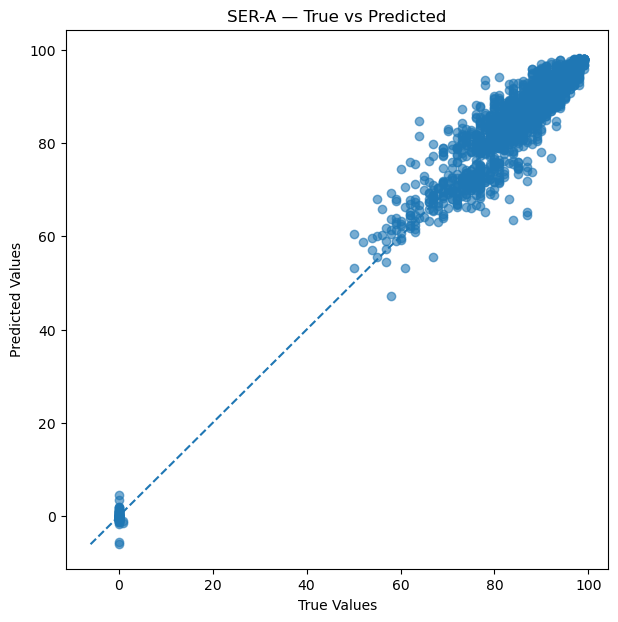

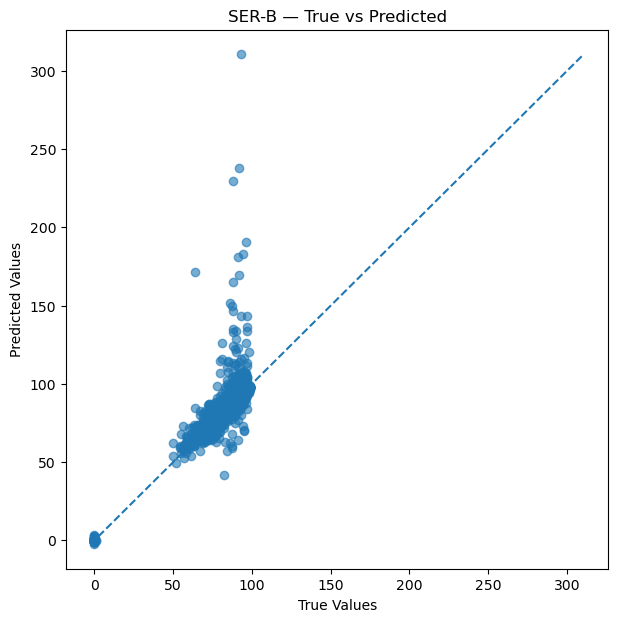

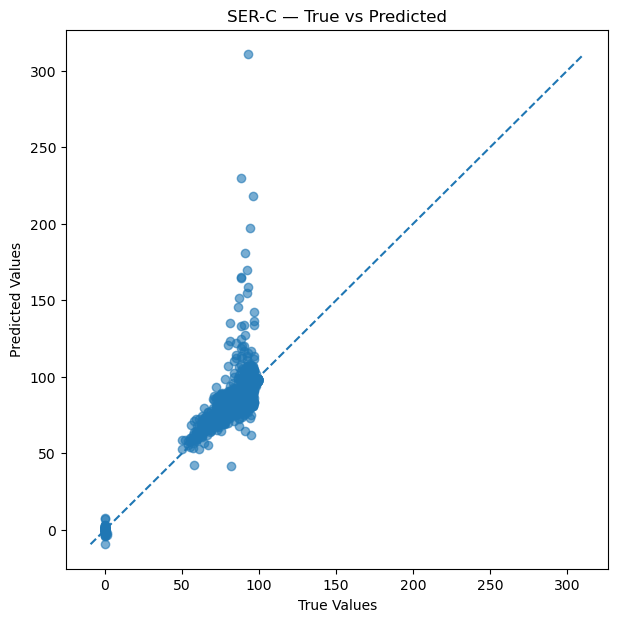

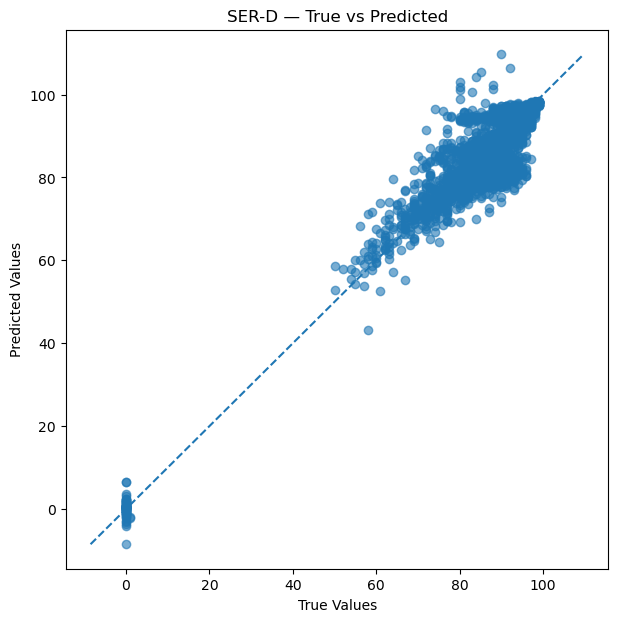

In [53]:
# ==========================================================
# SAVE TRUE VS PREDICTED FIGURES — ALL SER METHODS
# ==========================================================

methods_results = {
    "SER-A": results_A,
    "SER-B": results_B,
    "SER-C": results_C,
    "SER-D": results_D
}

for method_name, result in methods_results.items():

    plt.figure(figsize=(7, 7))

    plt.scatter(
        y_test,
        result["pred_blend"],
        alpha=0.6
    )

    min_val = min(y_test.min(), result["pred_blend"].min())
    max_val = max(y_test.max(), result["pred_blend"].max())

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle="--"
    )

    plt.xlabel("True Values")
    plt.ylabel("Predicted Values")
    plt.title(f"{method_name} — True vs Predicted")

    plt.savefig(
        f"../figures/cpuSm_{method_name}_true_vs_predicted.png",
        bbox_inches="tight"
    )

    plt.show()

### Save CSV

In [54]:
all_results.to_csv(
    "../results/cpuSm_results.csv",
    index=False
)